# Which pages keep losing the clicks they should be getting?

**A validated click-shortfall queue for a content portfolio** · Capstone, FlyRank ML Internship, Lane 4 (CTR opportunity scoring)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/neilivanorencia/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

## Abstract

Content teams need to know which existing pages are losing clicks they should be getting, and whether that loss will last long enough to be worth fixing. Using FlyRank's warehouse of 78.8 million daily Search Console records across about 50 client sites, each page's clicks were compared with what its exact position and its own site predict, and a page counted as a real shortfall only when it earned at most half of that and a negative binomial test ruled out bad luck. Real shortfalls proved persistent: a page with one this month was 3.8 to 4.8 times as likely to have one next month, including on a sealed month no analysis had touched. A transparent rule (rank by missed clicks) and a logistic regression model found those pages about equally well at the top of the list, 46 to 47 real shortfalls in 50 picks on the sealed month against a base rate of 2.2%, while the model ranked the rest of the list far better and the rule pointed at bigger click pools. The result is a monthly review list, ordered by the rule and labelled with the model's confidence, that a content editor can use as decision support.

**How to read it:** this notebook mirrors the deployed paper section by section. Each section states the finding in words, then a code cell pulls the evidence straight from the saved outputs of the weekly notebooks (`w03` to `w07`), so every number here can be traced to the run that produced it.


## Setup

**Method:** this cell finds the project folder (on Colab, it first clones the repository given in `REPO_URL`) and defines four small helpers: one to open a weekly notebook, one to pull a saved table by its title, one to pull a saved chart, and one to check that the numbers quoted in this notebook appear in the tables they come from. It reads no warehouse data and needs no token.


In [ ]:
import base64
import json
import os
import subprocess
import sys

from IPython.display import Image, Markdown, display

REPO_URL = "https://github.com/neilivanorencia/flyrank-ml-internship"  # the GitHub repository holding this project; used only when the notebooks are not found locally (for example on Colab)

# Locally, walk up to the project's top folder (the one holding work/notebooks); on Colab, clone the repository first.
while not os.path.isdir("work/notebooks") and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir("..")
if not os.path.isdir("work/notebooks") and "google.colab" in sys.modules and REPO_URL:
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/project"], check=True)
    os.chdir("/content/project")
assert os.path.isdir("work/notebooks"), "The weekly notebooks were not found; run this from the project folder or set REPO_URL."
NOTEBOOKS = "work/notebooks"
OUTPUTS = "work/outputs"


def notebook(name: str) -> dict:
    """Return a weekly notebook as a dictionary."""
    with open(f"{NOTEBOOKS}/{name}.ipynb", encoding="utf-8") as handle:
        return json.load(handle)


def saved_table(name: str, title: str, rows: int | None = None) -> str:
    """Return the saved Markdown table whose bold title starts with `title`, optionally cut to its first `rows` rows."""
    for cell in notebook(name)["cells"]:
        for output in cell.get("outputs", []):
            text = "".join(output.get("data", {}).get("text/markdown", []))
            if text.startswith(f"**{title}"):
                if rows is not None:
                    lines = text.splitlines()
                    start = next(i for i, line in enumerate(lines) if line.startswith(("| ---", "| :"))) + 1
                    text = "\n".join(lines[:start + rows])
                return text
    raise KeyError(f"{name}: no saved table titled '{title}'")


def saved_chart(name: str, number: int = 0) -> bytes:
    """Return the `number`-th saved chart of a weekly notebook as PNG bytes."""
    charts = [output["data"]["image/png"] for cell in notebook(name)["cells"] for output in cell.get("outputs", [])
              if "image/png" in output.get("data", {})]
    return base64.b64decode(charts[number])


def check(text: str, *values: str) -> None:
    """Fail loudly if a number quoted in this notebook is missing from the table it is quoted from."""
    missing = [value for value in values if value not in text]
    assert not missing, f"Quoted numbers not found in the source table: {missing}"


WEEKLY = {"w01_research_question": "ML-01 to ML-02", "w02_ml_task_framing": "ML-03", "w03_data_contract": "ML-04",
          "w03_feature_leakage_check": "ML-05", "w04_signal_audit": "ML-06", "w04_baseline_score": "ML-07",
          "w05_model": "ML-08", "w06_validation_audit": "ML-09", "w07_action_playbook": "ML-10"}
display(Markdown("**The weekly notebooks this capstone draws on**\n\n| Notebook | Card | Title | Findings |\n| --- | --- | --- | ---: |\n" + "\n".join(
    f"| `{name}` | {card} | {''.join(notebook(name)['cells'][0]['source']).splitlines()[0].lstrip('# ')} | "
    f"{sum(1 for cell in notebook(name)['cells'] if cell['cell_type'] == 'markdown' and ''.join(cell['source']).startswith('**Finding:**'))} |"
    for name, card in WEEKLY.items())))

**The weekly notebooks this capstone draws on**

| Notebook | Card | Title | Findings |
| --- | --- | --- | ---: |
| `w01_research_question` | ML-01 to ML-02 | ML-02 — Research Question and Provisional Lane | 6 |
| `w02_ml_task_framing` | ML-03 | ML-03 — Framing the Lane as an ML Task | 6 |
| `w03_data_contract` | ML-04 | ML-04 — Search Intelligence Data Contract | 19 |
| `w03_feature_leakage_check` | ML-05 | ML-05 — Feature Vector and Leakage/Privacy Check | 12 |
| `w04_signal_audit` | ML-06 | ML-06 — Signal Audit: Do the Flags Hold? | 9 |
| `w04_baseline_score` | ML-07 | ML-07 — Baseline Action Score and Top-20 Review | 7 |
| `w05_model` | ML-08 | ML-08 — Capstone Modeling Lane | 15 |
| `w06_validation_audit` | ML-09 | ML-09 — Validation and Research Claim Audit | 11 |
| `w07_action_playbook` | ML-10 | ML-10 — Content Action Playbook | 12 |

## 1. Question

**The research question.** _Which existing pages are earning far fewer clicks than their position and their own site predict, beyond what bad luck explains, and will that shortfall still be there next month?_

**The decision it supports.** Every month a content editor at FlyRank has thousands of live pages and time to review a few dozen. The question is where to look first. A page that ranks well but is not clicked is a cheap opportunity: the visibility is already earned, and a better title, description, or page can turn it into traffic. But a page can also miss clicks by chance for a month and recover on its own, and reviewing it wastes the editor's time.

**Why the obvious rule fails.** A common rule flags any page with at least 500 impressions, a position in the top 20, and a click-through rate below 0.5%. On this portfolio the normal click-through rate sits between 0.24% and 0.42% at every position from 1 to 20, below the 0.5% line everywhere, so the rule flags 74% to 88% of all visible pages, including most of the pages clicking exactly as expected. Judging a page needs its own position and its own site as the yardstick, and a test for luck.

**Method:** this cell shows the evidence for the failing rule from the signal audit: the normal click-through rate at each position against the flag's cutoff.


In [10]:
flag_curve = saved_table("w04_signal_audit", "Normal click-through by position")
display(Markdown(flag_curve))

**Normal click-through by position, and the flag's catch rate**

| Position | Pages | Normal click-through | Pages with 500+ impressions | Share flagged |
| ---: | ---: | ---: | ---: | ---: |
| 1 | 1,896 | 0.36% | 644 | 79% |
| 2 | 12,088 | 0.42% | 8,364 | 74% |
| 3 | 22,131 | 0.42% | 14,866 | 75% |
| 4 | 30,455 | 0.36% | 17,233 | 78% |
| 5 | 34,438 | 0.33% | 17,440 | 82% |
| 6 | 36,726 | 0.29% | 14,710 | 84% |
| 7 | 31,525 | 0.26% | 11,758 | 85% |
| 8 | 26,859 | 0.27% | 8,104 | 85% |
| 9 | 20,189 | 0.30% | 6,016 | 83% |
| 10 | 16,326 | 0.31% | 4,712 | 82% |
| 11 | 12,437 | 0.33% | 3,774 | 84% |
| 12 | 10,644 | 0.35% | 3,200 | 82% |
| 13 | 9,151 | 0.35% | 2,986 | 82% |
| 14 | 8,574 | 0.32% | 2,543 | 83% |
| 15 | 7,631 | 0.32% | 2,377 | 82% |
| 16 | 7,314 | 0.32% | 2,270 | 83% |
| 17 | 6,645 | 0.31% | 2,093 | 83% |
| 18 | 6,296 | 0.29% | 1,921 | 83% |
| 19 | 5,781 | 0.27% | 1,873 | 86% |
| 20 | 5,592 | 0.24% | 1,809 | 88% |

## 2. Data

**Source.** FlyRank's internship warehouse, release `v20260703`, read with DuckDB directly from Hugging Face (`FlyRank/internship-warehouse`, gated). Four tables: the daily page performance table (78,835,655 rows, one per page per day, Search Console and GA4), the page content table (519,606 pages, keyword research and content type), the client table (104 clients, history start dates), and a 90-day query table that was used only for diagnosis. All identifiers are pseudonymous hashes; no client name, URL, or search query appears anywhere in this work.

**Unit and windows.** One row is one page in one calendar-month pair: features from month M, outcome from month M+1. Three development pairs (February→March, March→April, April→May 2026) built and tuned everything; the May→June pair stayed sealed until a single final test.

**What was excluded, and why.**

- Days with an impossible position: 163,189 March page-days showed position 0, and 101,548 showed a position between 0 and 1, mostly on busy days, which made pages look top-ranked and inflated their expected clicks. Valid positions start at 1.
- Clients whose search history starts after the first day of month M, so every client is measured over a whole month.
- Pages without impressions and a valid position in both months of a pair.
- Pages FlyRank optimized during the pair: someone already acted on them, so the next month cannot judge them.
- From the content table, every field that could postdate month M: word counts and edit dates come from a July 2026 snapshot, and optimization dates and eligibility flags record FlyRank's own later decisions. Only keyword-research fields, fixed before a page is written, are features.

**Method:** this cell shows the four labelled month pairs the work rests on.


In [11]:
pairs_table = saved_table("w07_action_playbook", "Labelled month pairs")
check(pairs_table, "114,972", "155,707", "157,530", "137,275", "8,465", "10,031", "6,525", "2,978")
display(Markdown(pairs_table))

**Labelled month pairs (α = 0.039)**

| Pair | Rows | Real shortfalls | Base rate | Used to train |
| --- | ---: | ---: | ---: | --- |
| 2026-02 → 2026-03 | 114,972 | 8,465 | 7.4% | back-test and live model |
| 2026-03 → 2026-04 | 155,707 | 10,031 | 6.4% | back-test and live model |
| 2026-04 → 2026-05 | 157,530 | 6,525 | 4.1% | back-test and live model |
| 2026-05 → 2026-06 | 137,275 | 2,978 | 2.2% | live model only |

## 3. Methodology

**Expected clicks.** For each page and month: impressions × the pooled click-through rate of its position bin (each position from 1 to 10, then 11 to 20, 21 to 50, and beyond) × its client's factor (the site's clicks ÷ its expected clicks, +1 on both sides). The yardstick is therefore the page's own position on its own site.

**The label (a real shortfall).** Clicks in a month at most half of expected, _and_ a negative binomial test saying luck explains the gap less than 5% of the time. Clicks vary far more than a Poisson count allows (1.48 times as much for pages with 10 to 29 clicks, 41 times for pages with 1,000 or more), so the spread factor α was estimated by the method of moments on pages whose position barely moved, once per development pair (0.050, 0.032, 0.039), and the median, 0.039, was locked. The target is a real shortfall in month M+1.

**Baseline (rule B).** Missed clicks in month M (expected minus actual), counted only for pages already short by the target's rule in month M. It was chosen from three candidate rules by a criterion fixed in advance and then frozen.

**Model.** Logistic regression on 25 features: month-M traffic (impressions, clicks, click-through, position, its daily spread, days with impressions, expected clicks), rule B's two month-M signals, and keyword research (search volume, competition, cost per click, intent, content type, keyword length). A depth-3 tree, a random forest, and gradient boosting were trained the same way for comparison.

**Validation.** Walk-forward and grouped by client: each test pair is scored by models trained only on earlier pairs and only on other clients, so every test page comes from a month and a site the model never saw. A model beats rule B only if its mean Precision@50 is more than 0.02 higher, or within 0.02 and higher on Capture@50 (the share of next month's missed clicks held by the top 50). The base rate is printed beside every precision. Uncertainty comes from 1,000 client-level bootstrap resamples, and a sealed month (May→June) was scored once at the end.

**Leakage checks.** Scrambling every month M+1 column, the target, and every product field leaves all 25 features unchanged; no feature crosses the 0.90 separation alarm once page size is held fixed; a planted leak lifts the score sharply, so the harness catches leaks; and no test page appears in its model's training rows.

**Method:** this cell shows the leakage audit's summary and how much looser validation designs would have flattered the model.


In [12]:
leakage = saved_table("w06_validation_audit", "Leakage audit (all checks passed)")
designs = saved_table("w06_validation_audit", "Means over the two test pairs, and how far each design sits above the strictest")
check(designs, "0.920", "0.890")
display(Markdown(leakage))
display(Markdown(designs))

**Leakage audit (all checks passed)**

| Measure | Value |
| --- | --- |
| 1. features available before the decision point | yes: scrambling every month M+1 column and the target leaves all 25 features unchanged |
| 2. feature and target windows | disjoint calendar months; the month M+1 versions of the new features are shown above for contrast |
| 3. product flags | none is a feature; scrambling them leaves the features unchanged |
| 4. derived fields encoding the target | 2 feature(s) at or above the 0.90 alarm; the planted leak is caught |
| 5. related rows across train and test | 0 test pages in their model's training rows under the strictest design |

**Means over the two test pairs, and how far each design sits above the strictest**

| Design | Mean Precision@50 | Above the strictest design | Mean ROC-AUC | ROC-AUC above the strictest | Mean Capture@50 |
| --- | ---: | ---: | ---: | ---: | ---: |
| Random rows | 0.920 | +0.030 | 0.935 | +0.006 | 3.26% |
| Client-grouped, same months | 0.910 | +0.020 | 0.933 | +0.005 | 3.19% |
| Time-forward, same clients | 0.910 | +0.020 | 0.932 | +0.004 | 3.32% |
| Walk-forward + client | 0.890 | +0.000 | 0.928 | +0.000 | 3.59% |
| Rule B (no training) | 0.800 | -0.090 | 0.758 | -0.170 | 5.60% |

## 4. Results (vs baseline)

**Real shortfalls persist.** Among pages with 1,000 to 9,999 impressions, a page with a real shortfall in one month had one again the next month 28% to 51% of the time, against 6% to 13% for pages without one: 3.8 to 4.8 times as often, on the sealed month too. This is what makes a monthly queue worth having.

**On the development pairs,** logistic regression led rule B on mean Precision@50 (0.890 against 0.800), but its top 50 held fewer of next month's missed clicks (3.59% against 5.60%).

**On the sealed month,** both found real shortfalls at nearly the same rate: Precision@50 of 0.94 for the model against 0.92 for rule B, with a base rate of 2.2%, about 46 to 47 real shortfalls in 50 picks where random picks would find one. The gap of 0.02 sits inside the margin fixed in advance, so Capture@50 decided, and rule B's top 50 held clearly more of June's missed clicks (19.2% against 12.4%). **By the rule fixed before the test, the model did not beat rule B.** The model still ranks the whole list far better (ROC-AUC 0.915 against 0.711).

**How certain.** The model led in all three test sets (+0.06, +0.12, +0.02), but every 95% interval crosses zero; rule B's lead on missed clicks is clear in all three. At the top of the queue the two are level on hits, and rule B reliably finds the bigger click pools.

**Method:** this cell shows the persistence evidence, the development comparison, the sealed test, and the bootstrap intervals, each from the notebook that computed it.


In [13]:
persistence = saved_table("w06_validation_audit", "Claim 2 evidence")
development = saved_table("w05_model", "Means over the two test pairs, and the verdict")
sealed = saved_table("w06_validation_audit", "The sealed pair")
bootstrap = saved_table("w06_validation_audit", "Logistic regression minus rule B, client-level bootstrap")
check(persistence, "3.9x", "4.5x", "3.8x", "4.8x")
check(development, "0.800", "0.890", "5.60%", "3.59%")
check(sealed, "0.94", "0.92", "19.2%", "12.4%", "0.915", "0.711", "2.2%")
check(bootstrap, "+0.06", "+0.12", "+0.02")
for table in (persistence, development, sealed, bootstrap):
    display(Markdown(table))

**Claim 2 evidence: shortfalls in consecutive months, pages with 1,000 to 9,999 impressions**

| Pair | Pages short in month M | Short again in month M+1 | Pages not short | Short in month M+1 | Ratio |
| --- | ---: | ---: | ---: | ---: | ---: |
| 2026-02 → 2026-03 | 6,472 | 51.1% | 21,259 | 13.2% | 3.9x |
| 2026-03 → 2026-04 | 8,662 | 43.9% | 30,355 | 9.8% | 4.5x |
| 2026-04 → 2026-05 | 6,891 | 32.6% | 22,779 | 8.5% | 3.8x |
| 2026-05 → 2026-06 (sealed) | 2,857 | 28.0% | 14,063 | 5.8% | 4.8x |

**Means over the two test pairs, and the verdict**

| Scorer | Mean Precision@50 | Gap to rule B | Mean Precision@20 | Mean Capture@50 | Mean Precision@50, 1,000 to 9,999 | Mean average precision | Beats rule B | Carried forward |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | --- | --- |
| Rule B (baseline) | 0.800 | +0.000 | 0.850 | 5.60% | 0.700 | 0.385 |  |  |
| Logistic regression | 0.890 | +0.090 | 0.875 | 3.59% | 0.740 | 0.509 | yes | yes |
| Decision tree | 0.531 | -0.269 | 0.531 | 0.46% | 0.454 | 0.415 | no |  |
| Random forest | 0.810 | +0.010 | 0.875 | 0.97% | 0.690 | 0.521 | no |  |
| Gradient boosting | 0.820 | +0.020 | 0.775 | 1.31% | 0.750 | 0.511 | no |  |

**The sealed pair: 137,275 pages, 2,978 real shortfalls, α = 0.039**

| Scorer | Precision@50 | Precision@20 | Capture@50 | Precision@50, 1,000 to 9,999 impressions | ROC-AUC | Average precision | Base rate |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Rule B (baseline) | 0.92 | 0.90 | 19.2% | 0.68 | 0.711 | 0.294 | 2.2% |
| Logistic regression, unseen clients (primary) | 0.94 | 1.00 | 12.4% | 0.56 | 0.915 | 0.375 | 2.2% |
| Logistic regression, all clients (deployment) | 0.94 | 1.00 | 14.6% | 0.56 | 0.917 | 0.378 | 2.2% |

**Logistic regression minus rule B, client-level bootstrap (1,000 resamples, 95% intervals)**

| Test set | Precision@50 gap | 95% interval | Resamples with the model ahead | Capture@50 gap (points) | Capture 95% interval (points) |
| --- | ---: | --- | ---: | ---: | --- |
| 2026-03 → 2026-04 | +0.06 | -0.10 to +0.18 | 77% | -1.4 | -3.2 to -0.4 |
| 2026-04 → 2026-05 | +0.12 | -0.04 to +0.18 | 87% | -2.6 | -6.1 to -0.0 |
| 2026-05 → 2026-06 (sealed) | +0.02 | -0.08 to +0.12 | 66% | -6.8 | -9.8 to -1.3 |

## 5. Limitations

- **No measured gain.** The work shows where clicks are missing and that the gap tends to last, not how many clicks a fix recovers. Some shortfalls come from results-page features (ads, AI answers) that no rewrite can beat. Measuring the gain needs an experiment: fix a random half of a month's list and compare it with the other half.
- **Association, not cause.** Persistence and every pattern here are observed in one portfolio over five months; none is a causal claim.
- **Fifty pages per test.** Each Precision@50 rests on 50 pages, so the intervals are wide and no single lead of the model is clear of chance.
- **One sealed month.** It removes the risk of tuning towards the test, but cannot show behaviour across seasons; the position mix has already drifted since February, past the monitoring trigger.
- **Small pages are rarely judged.** A real shortfall needs enough traffic to rule out luck, so the queue reaches a quarter of pages with 10,000 or more impressions but only 0.1% of the smallest.
- **Visibility loss is a different problem.** Most of the model's misses were pages that lost their search visibility the next month, which no click-based score can foresee.
- **Changes after earlier runs.** Gradient boosting's stopping rule and rule B's two features were added after reading earlier development runs; the comparison rule and the sealed test were fixed in advance.

**Method:** this cell shows two of these limits in numbers: who the queue reaches by page size, and the monitoring history with its drift trigger.


In [14]:
reach = saved_table("w07_action_playbook", "Who the queue reaches, by page size")
monitoring = saved_table("w07_action_playbook", "Monitoring history against the triggers")
check(reach, "25.9%", "0.1%")
check(monitoring, "0.561", "Drift")
display(Markdown(reach))
display(Markdown(monitoring))

**Who the queue reaches, by page size (June 2026)**

| Impressions in June | Scored pages | Share in the queue | In the review list |
| --- | ---: | ---: | ---: |
| Under 100 | 99,834 | 0.1% | 0 |
| 100 to 999 | 67,000 | 2.0% | 0 |
| 1,000 to 9,999 | 30,905 | 13.2% | 3 |
| 10,000 or more | 4,009 | 25.9% | 47 |

**Monitoring history against the triggers**

| Month pair | Review list hit rate | Base rate | α | PSI, impressions | PSI, position | Misses that lost visibility | Triggers |
| --- | --- | --- | --- | ---: | ---: | --- | --- |
| 2026-02 → 2026-03 | 68% | 7.4% | 0.050 | 0.000 | 0.000 | 31% | none |
| 2026-03 → 2026-04 | 80% | 6.4% | 0.032 | 0.021 | 0.052 | 40% | none |
| 2026-04 → 2026-05 | 84% | 4.1% | 0.039 | 0.038 | 0.148 | 25% | none |
| 2026-05 → 2026-06 | 88% | 2.2% | 0.048 | 0.204 | 0.561 | 17% | Drift |
| 2026-06 (live, no outcome yet) | n/a | n/a | n/a | 0.075 | 0.299 | n/a | Drift |

## 6. Ranked recommendations

**The playbook.** Once a month, rank every page with a real shortfall by its missed clicks (rule B), take the first 50 with at most 10 from any one client, label each with the model's confidence, and give each one action, chosen in this order:

1. **Check indexing and rankings first** when impressions halved since the previous month: the page is leaving search, and a rewrite will not help.
2. **Wait and re-check next month** when the daily position spread is 5 places or more: these pages repeated least often (19%).
3. **Review site-wide** when the whole site clicks at under half of what its positions predict.
4. **Check the results page first** for buying-intent keywords, where ads and shopping results may take the clicks.
5. **Improve the content** when GA4 shows most visitors leaving without engaging.
6. **Rewrite the title and description** otherwise.

**Evidence that it works.** On the May→June back-test, 16 of the 17 review-list pages FlyRank did not touch (94%) were real shortfalls again in June, and FlyRank's own team optimized 33 of the 50 during those two months. The confidence label orders outcomes correctly (62%, 33%, and 16% repeated for high, medium, and low), though its numbers run 10 to 15 points high. A longer list holds more of the missed clicks at a lower hit rate (30% of June's missed clicks at 500 pages, with 81% hits).

**What a person must check** before acting: the live results page for the main keyword, whether the page is still indexed, and whether it changed since the month the list was built from. Nothing is published, de-indexed, or promised automatically.

**Method:** this cell shows the back-test, the confidence check, and the first twelve pages of the July review list built from June 2026 data.


In [15]:
tradeoff = saved_table("w07_action_playbook", "Queue size against what it captured in June")
confidence = saved_table("w07_action_playbook", "Confidence label against the June outcome")
july = saved_table("w07_action_playbook", "Review list for July", rows=12)
check(tradeoff, "94%", "81%", "30.3%")
check(confidence, "62%", "33%", "16%")
for table in (tradeoff, confidence, july):
    display(Markdown(table))

**Queue size against what it captured in June (May back-test)**

| List | Pages | Optimized by FlyRank | Vanished from search | Real shortfall again, all picks | Real shortfall again, pages FlyRank left alone | Share of June's missed clicks | Clients |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| Top 20 | 20 | 14 | 0 | 30% | 100% | 5.1% | 6 |
| Top 50 | 50 | 32 | 0 | 34% | 94% | 12.5% | 11 |
| Top 100 | 100 | 62 | 0 | 34% | 89% | 15.9% | 11 |
| Top 200 | 200 | 125 | 0 | 32% | 85% | 21.4% | 15 |
| Top 500 | 500 | 306 | 0 | 31% | 81% | 30.3% | 19 |
| Top 50, at most 10 per client (chosen) | 50 | 33 | 0 | 32% | 94% | 9.2% | 11 |

**Confidence label against the June outcome (May back-test)**

| Scope | Confidence | Pages | Model's average probability | Real shortfall again, all pages | Pages FlyRank left alone | Real shortfall again, pages FlyRank left alone |
| --- | --- | ---: | --- | --- | ---: | --- |
| Whole queue | High | 2267 | 77% | 25% | 919 | 62% |
| Whole queue | Medium | 3453 | 43% | 14% | 1482 | 33% |
| Whole queue | Low | 2412 | 21% | 9% | 1359 | 16% |
| Review list | High | 50 | 96% | 32% | 17 | 94% |
| Review list | Medium | 0 | n/a | n/a | 0 | n/a |
| Review list | Low | 0 | n/a | n/a | 0 | n/a |

**Review list for July (June 2026 data, 50 pages, at most 10 per client)**

| Review rank | Action | Reason codes | Confidence | Probability | Missed clicks in June | Impressions | Position | Position spread | Search intent |
| ---: | --- | --- | --- | ---: | ---: | ---: | ---: | ---: | --- |
| 1 | Review site-wide | real_shortfall, client_wide_low_ctr, low_engagement | High | 99% | 13,201 | 585,712 | 2.2 | 0.3 | informational |
| 2 | Check the search results page first | real_shortfall, commercial_intent | High | 100% | 12,778 | 292,416 | 1.9 | 0.7 | transactional |
| 3 | Review site-wide | real_shortfall, client_wide_low_ctr, low_engagement | High | 99% | 12,598 | 591,696 | 2.3 | 0.2 | informational |
| 4 | Review site-wide | real_shortfall, client_wide_low_ctr, low_engagement | High | 99% | 6,702 | 269,943 | 2.1 | 0.1 | informational |
| 5 | Rewrite the title and description | real_shortfall | High | 99% | 6,457 | 157,289 | 1.8 | 0.1 | informational |
| 6 | Check the search results page first | real_shortfall, commercial_intent, low_engagement | High | 97% | 3,656 | 116,908 | 1.9 | 0.3 | transactional |
| 7 | Check the search results page first | real_shortfall, commercial_intent | High | 99% | 3,359 | 75,720 | 2.5 | 0.6 | transactional |
| 8 | Review site-wide | real_shortfall, client_wide_low_ctr, low_engagement | High | 98% | 2,949 | 119,228 | 2.4 | 0.1 | informational |
| 9 | Improve the content | real_shortfall, low_engagement | High | 95% | 2,634 | 78,792 | 1.9 | 0.2 | informational |
| 10 | Rewrite the title and description | real_shortfall | High | 99% | 2,578 | 63,690 | 2.0 | 0.2 | informational |
| 11 | Review site-wide | real_shortfall, client_wide_low_ctr, low_engagement | High | 96% | 2,479 | 139,884 | 1.8 | 0.1 | informational |
| 12 | Review site-wide | real_shortfall, client_wide_low_ctr, low_engagement | High | 97% | 2,419 | 103,230 | 2.1 | 0.2 | informational |

## 7. Artifacts the paper embeds

The paper uses three charts, one for each step of its story: the problem (a flat rule misjudges pages), the honest result (model and rule level at the top), and the resolution (a review list sized on purpose).

**Method:** this cell collects the first two charts from the notebooks that drew them and saves them to `work/outputs/` under the names the paper uses. The third is the action playbook's own export, `queue_size_tradeoff.png`, already in `work/outputs/`, so it is shown from there rather than saved twice (from the playbook notebook's saved output if the file is not present).


**Figure 1: Flat CTR Rule** (from `w04_signal_audit`). A page clicking at the normal rate fails the 0.5% flag at every position from 1 to 20.

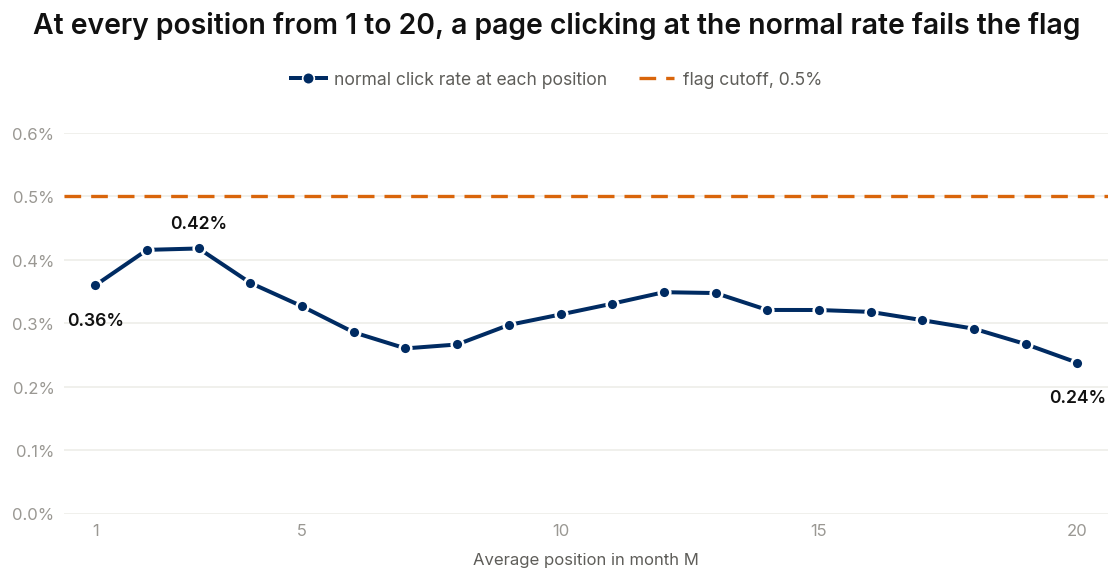

**Figure 2: Model vs Rule** (from `w06_validation_audit`). The model leads rule B in every test set, but no single lead is clear of chance.

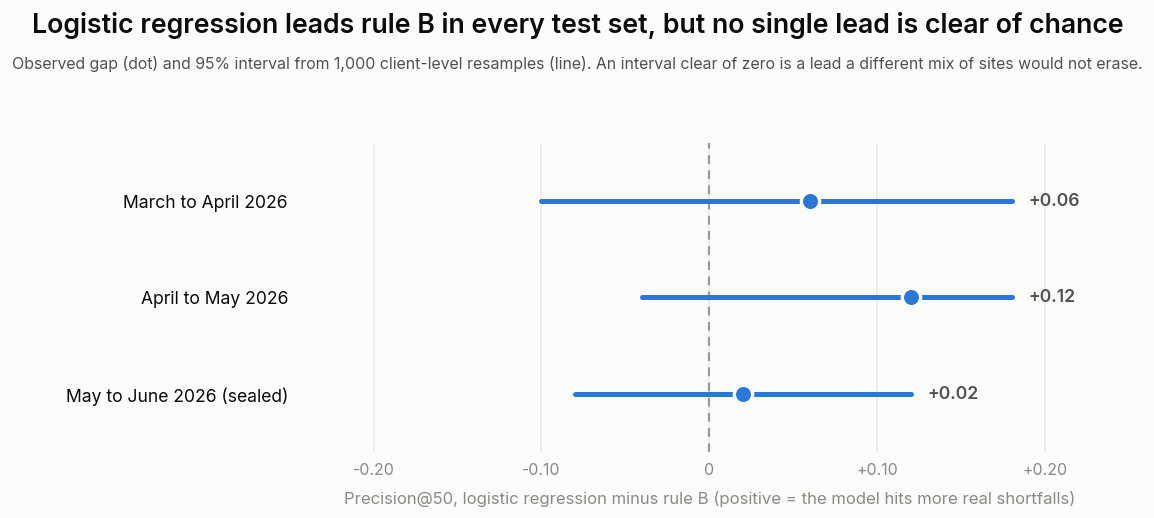

**Figure 3: Queue Size Tradeoff** (exported by `w07_action_playbook`). A longer list holds more of the missed clicks at a lower hit rate; 50 pages keeps hits near 94%.

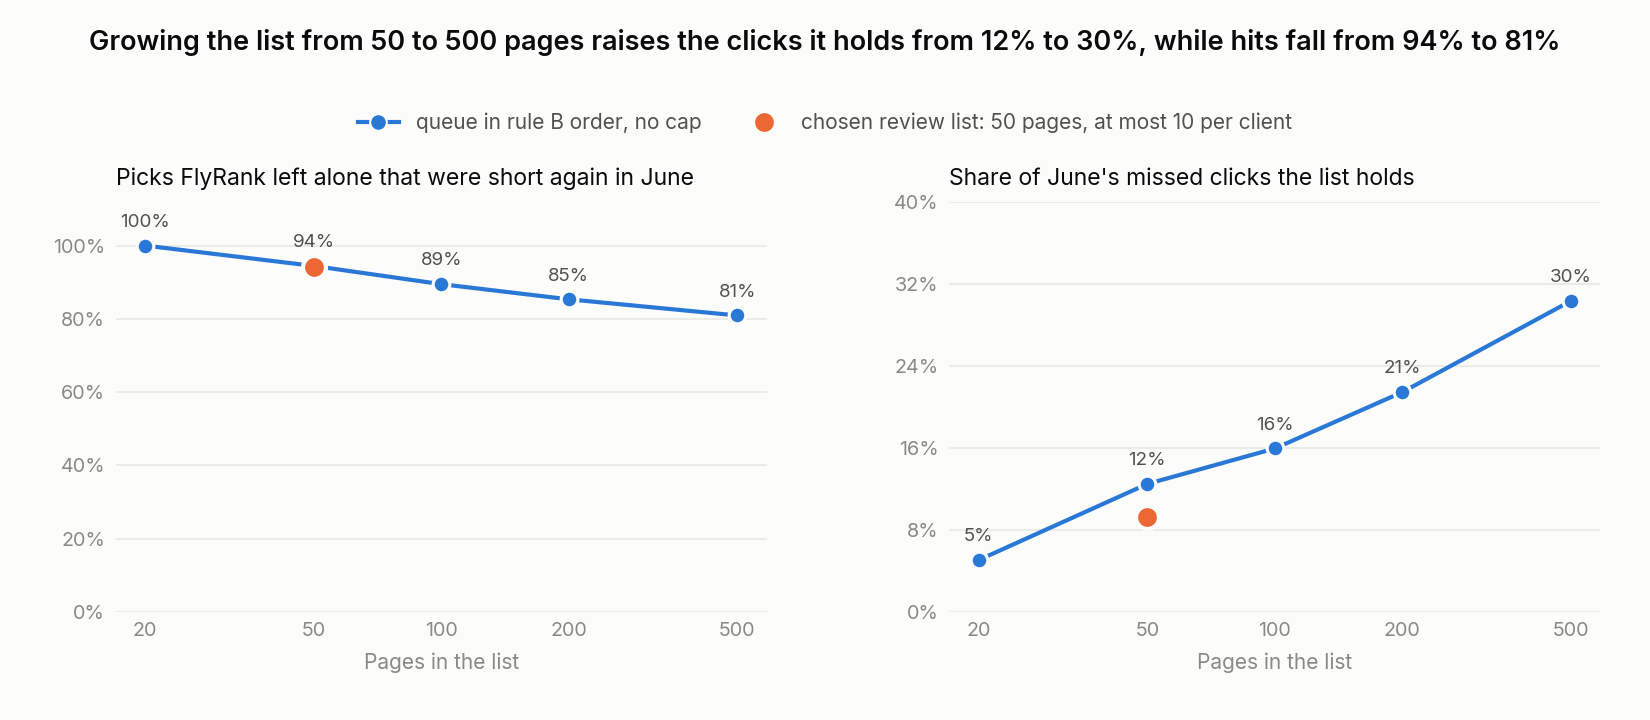

In [16]:
FIGURES = {"Flat CTR Rule": ("w04_signal_audit", "A page clicking at the normal rate fails the 0.5% flag at every position from 1 to 20."),
           "Model vs Rule": ("w06_validation_audit", "The model leads rule B in every test set, but no single lead is clear of chance.")}
os.makedirs(OUTPUTS, exist_ok=True)
for number, (file_name, (source, caption)) in enumerate(FIGURES.items(), start=1):
    picture = saved_chart(source)
    with open(f"{OUTPUTS}/{file_name}", "wb") as handle:
        handle.write(picture)
    display(Markdown(f"**Figure {number}: {file_name}** (from `{source}`). {caption}"))
    display(Image(picture, width=900))

# Figure 3 is the action playbook's own export; it is shown, not copied.
PLAYBOOK_FIGURE = f"{OUTPUTS}/queue_size_tradeoff.png"
if os.path.exists(PLAYBOOK_FIGURE):
    with open(PLAYBOOK_FIGURE, "rb") as handle:
        picture = handle.read()
else:
    picture = saved_chart("w07_action_playbook")
display(Markdown("**Figure 3: Queue Size Tradeoff** (exported by `w07_action_playbook`). "
                 "A longer list holds more of the missed clicks at a lower hit rate; 50 pages keeps hits near 94%."))
display(Image(picture, width=900))

### Reproducibility and data credit

- **Notebooks:** `work/notebooks/w01` to `w07` hold every step, each run top to bottom on Google Colab with its outputs saved; this notebook re-reads those outputs and checks every number it quotes.
- **Rerunning:** the weekly notebooks read the warehouse with a Hugging Face token stored as an environment variable or a Colab Secret named `HF_TOKEN`, never in a cell. Heavy month scans are cached under `work/outputs/w03_cache/`.
- **Seeds and versions:** seed 42 everywhere; the modelling runs used scikit-learn 1.6.1, pandas 2.2.3, and numpy 2.1.3 on Colab.
- **Data credit:** data provided by [FlyRank](https://flyrank.ai) through the FlyRank ML Internship warehouse (release `v20260703`), pseudonymized before release. No raw client data, URL, or query is included in this repository.


## ML-12: talk-through, social post, and employer summary

### Five-minute talk-through

A plan for presenting the project live, in an interview, a mentor call, or the internship showcase; nothing is recorded.

| Time         | What to show                                                              | What to say                                                                                                                                                          |
| ------------ | ------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| 0:00 to 0:40 | The question and one page: high impressions, position 2, almost no clicks | Editors have thousands of pages and time for a few dozen; which ones are really losing clicks?                                                                       |
| 0:40 to 1:30 | Chart 1, the flat 0.5% rule                                               | The common rule flags most pages, including normal ones; each page needs its own position and site as the yardstick, plus a luck test                                |
| 1:30 to 2:20 | The label and the persistence table                                       | A real shortfall is at most half of expected and beyond luck; it repeats next month 3.8 to 4.8 times as often, on a sealed month too                                 |
| 2:20 to 3:20 | The sealed test and Chart 2                                               | The model and a transparent rule are level at the top (0.94 against 0.92); the rule finds bigger click pools; the model did not beat it by the rule fixed in advance |
| 3:20 to 4:20 | Chart 3 and the July review list                                          | 50 pages a month, about 94% real when untouched, one action each, confidence from the model, a human check before anything ships                                     |
| 4:20 to 5:00 | Limits and next step                                                      | No measured gain yet; the next step is a randomized test of fixes, and retraining now that drift crossed its trigger                                                 |

### Social post (LinkedIn)

I built a machine learning model to find web pages that are losing clicks. A simple rule matched it.

Every company with a website has more pages than time to fix them. Based upon it, a question was formed: which pages get far fewer clicks from Google than they should, and will that still be true next month? I worked with 78.8 million daily records of Google search data across about 50 websites.

Here's what the data showed:

— Ranking higher doesn't always mean more clicks. Pages in first place on Google were clicked less often than pages in second and third place, and pages at the top of the second page of results were clicked more often than pages near the bottom of the first page.

— The website matters as much as the ranking. In the same spot on Google, some websites were clicked about 4 times as often as others. So a one-size-fits-all rule, like fix any page where fewer than 1 in 200 people click, flags most pages, including healthy ones.

— Clicks go up and down a lot on their own. Many pages that look like they are underperforming are simply having an unlucky month.

So I compared every page with what it should get for its spot on Google and its own website, and only counted it as a real problem when it got half of that or less, and the gap was too big to be bad luck.

Then I tested the approach on websites and months it had never seen, and once more on a month I kept untouched until the very end. Here's what that showed:

● Real problems tend to stick around. A page with a real problem this month was about 4 times as likely to still have it next month.

● A simple rule (start with the pages missing the most clicks) did as well as the machine learning model. Out of their top 50 picks, 46 and 47 were real problems, when random picks would find about one.

● The rule found the pages with the most clicks to win back, while the model was better at ordering the rest of the list.

Here's what a content team can use from it: a monthly list of 50 pages to look at first, each with a suggested first step, such as rewriting the title people see on Google, improving the page itself, or simply waiting. When I checked it against the following month, 94% of the listed pages that nobody had touched were still losing clicks.

The lesson I'm keeping: give the simple approach a fair chance before trusting a complex one, and say so when it holds up.

Built during my machine learning internship at FlyRank AI, using their real, privacy-protected search data.

#Analytics #ContentStrategy #DataScience #FlyRank #GoogleSearchConsole #MachineLearning #ModelValidation #Python #SEO #StatisticalModeling

### Employer-facing summary (three sentences)

I built a monthly click-shortfall review queue for a content portfolio from 78.8 million daily Google Search Console records across about 50 client sites, using DuckDB, a negative-binomial luck test, and walk-forward, client-grouped validation with a sealed final month. Shortfalls defined against each page's own position and site proved persistent (about 4 times as likely to repeat), and on the sealed month the queue's top 50 held 46 to 47 real shortfalls against a 2.2% base rate. I reported honestly that a transparent rule matched the machine-learning model at the top of the queue, and turned both into a playbook with reason codes, confidence labels, human checks, and drift monitoring.


## Self-check

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [x] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the <https://flyrank.ai> link) at the bottom.
- [x] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
